<a href="https://colab.research.google.com/github/josecano8910/tavns-mindfulness-hrv-pipeline/blob/main/analysis/artifact_filter_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Artifacts detected: 2 beats (16.7%)
Raw RR:     [ 805.  812.  798. 1350.  810.  802.  795.  380.  808.  815.  799.  804.]
Cleaned RR: [805.  812.  798.  804.  810.  802.  795.  801.5 808.  815.  799.  804. ]
Raw RMSSD (corrupted):  294.25 ms
Clean RMSSD (filtered): 8.76 ms


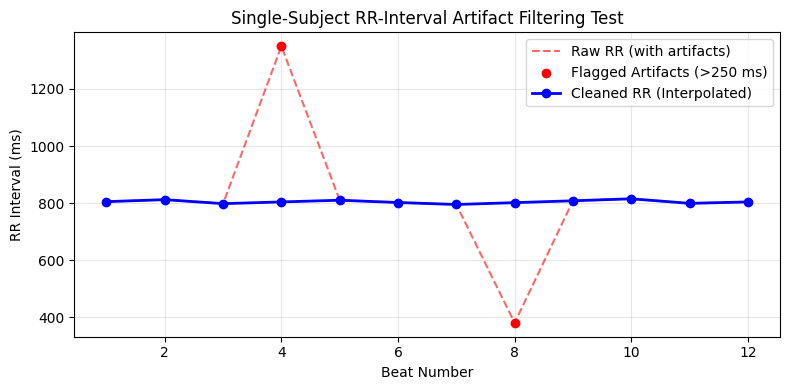

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Simulate 12 heartbeats (in ms) with two sensor glitches (1350 ms and 380 ms)
raw_rr = np.array([805, 812, 798, 1350, 810, 802, 795, 380, 808, 815, 799, 804], dtype=float)

# 2. Kubios-style threshold artifact filter (> 250 ms from rolling median)
def clean_rr_artifacts(rr_series, threshold_ms=250):
    rr = pd.Series(rr_series.copy())
    local_median = rr.rolling(window=5, center=True, min_periods=1).median()
    is_artifact = np.abs(rr - local_median) > threshold_ms
    artifact_pct = is_artifact.mean() * 100
    cleaned_rr = rr.mask(is_artifact).interpolate(method='linear').bfill().ffill()
    return cleaned_rr.to_numpy(), is_artifact.to_numpy(), artifact_pct

# 3. Compute RMSSD (vagal tone metric) before vs. after cleaning
def compute_rmssd(rr_series):
    diffs = np.diff(rr_series)
    return float(np.sqrt(np.mean(diffs ** 2)))

cleaned_rr, flags, pct = clean_rr_artifacts(raw_rr, threshold_ms=250)
raw_rmssd = compute_rmssd(raw_rr)
clean_rmssd = compute_rmssd(cleaned_rr)

print(f"Artifacts detected: {flags.sum()} beats ({pct:.1f}%)")
print("Raw RR:    ", raw_rr)
print("Cleaned RR:", np.round(cleaned_rr, 1))
print(f"Raw RMSSD (corrupted):  {raw_rmssd:.2f} ms")
print(f"Clean RMSSD (filtered): {clean_rmssd:.2f} ms")

# 4. Plot the before-and-after comparison and save it as a PNG
beats = np.arange(1, len(raw_rr) + 1)

plt.figure(figsize=(8, 4))
plt.plot(beats, raw_rr, 'r--', alpha=0.6, label='Raw RR (with artifacts)')
plt.scatter(beats[flags], raw_rr[flags], color='red', zorder=5, label='Flagged Artifacts (>250 ms)')
plt.plot(beats, cleaned_rr, 'b-o', linewidth=2, label='Cleaned RR (Interpolated)')

plt.title('Single-Subject RR-Interval Artifact Filtering Test')
plt.xlabel('Beat Number')
plt.ylabel('RR Interval (ms)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("artifact_cleaning_example.png", dpi=300)
plt.show()
